# Exploración gráfica de ventas

Ejecuta las celdas en orden. El cuaderno carga automáticamente la base de ventas y crea seis gráficos para explorar tendencias, distribuciones y relaciones.

In [7]:
import csv
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BASE_DIR = Path.cwd()
candidates = list(BASE_DIR.rglob("ventas_mensuales_tratada.csv"))
if not candidates:
    candidates = list(BASE_DIR.rglob("ventas_mensuales.csv"))
if not candidates:
    raise FileNotFoundError("No se encontro ventas_mensuales.csv en la carpeta actual")

DATA_FILE = candidates[0]
numeric_columns = {"anio", "mes", "cantidad", "precio", "descuento_pct", "ventas"}
text_columns = {"periodo", "region", "sucursal", "categoria", "producto", "laboratorio"}

with DATA_FILE.open("r", encoding="utf-8-sig", newline="") as source:
    reader = csv.DictReader(source)
    fieldnames = reader.fieldnames or []
    rows = list(reader)

clean_rows = []
for source_row in rows:
    row = dict(source_row)
    for column in text_columns & set(fieldnames):
        row[column] = (row.get(column) or "").strip()
    for column in numeric_columns & set(fieldnames):
        try:
            row[column] = float(row[column])
        except (TypeError, ValueError):
            row[column] = None
    if all(isinstance(row.get(column), (int, float)) for column in ("ventas", "cantidad", "precio", "descuento_pct")):
        clean_rows.append(row)

if not clean_rows:
    raise ValueError("La base no tiene registros numericos validos para graficar")

print(f"Fuente: {DATA_FILE}")
print(f"Registros graficados: {len(clean_rows):,}")

Fuente: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_mensuales_tratada.csv
Registros graficados: 39,013


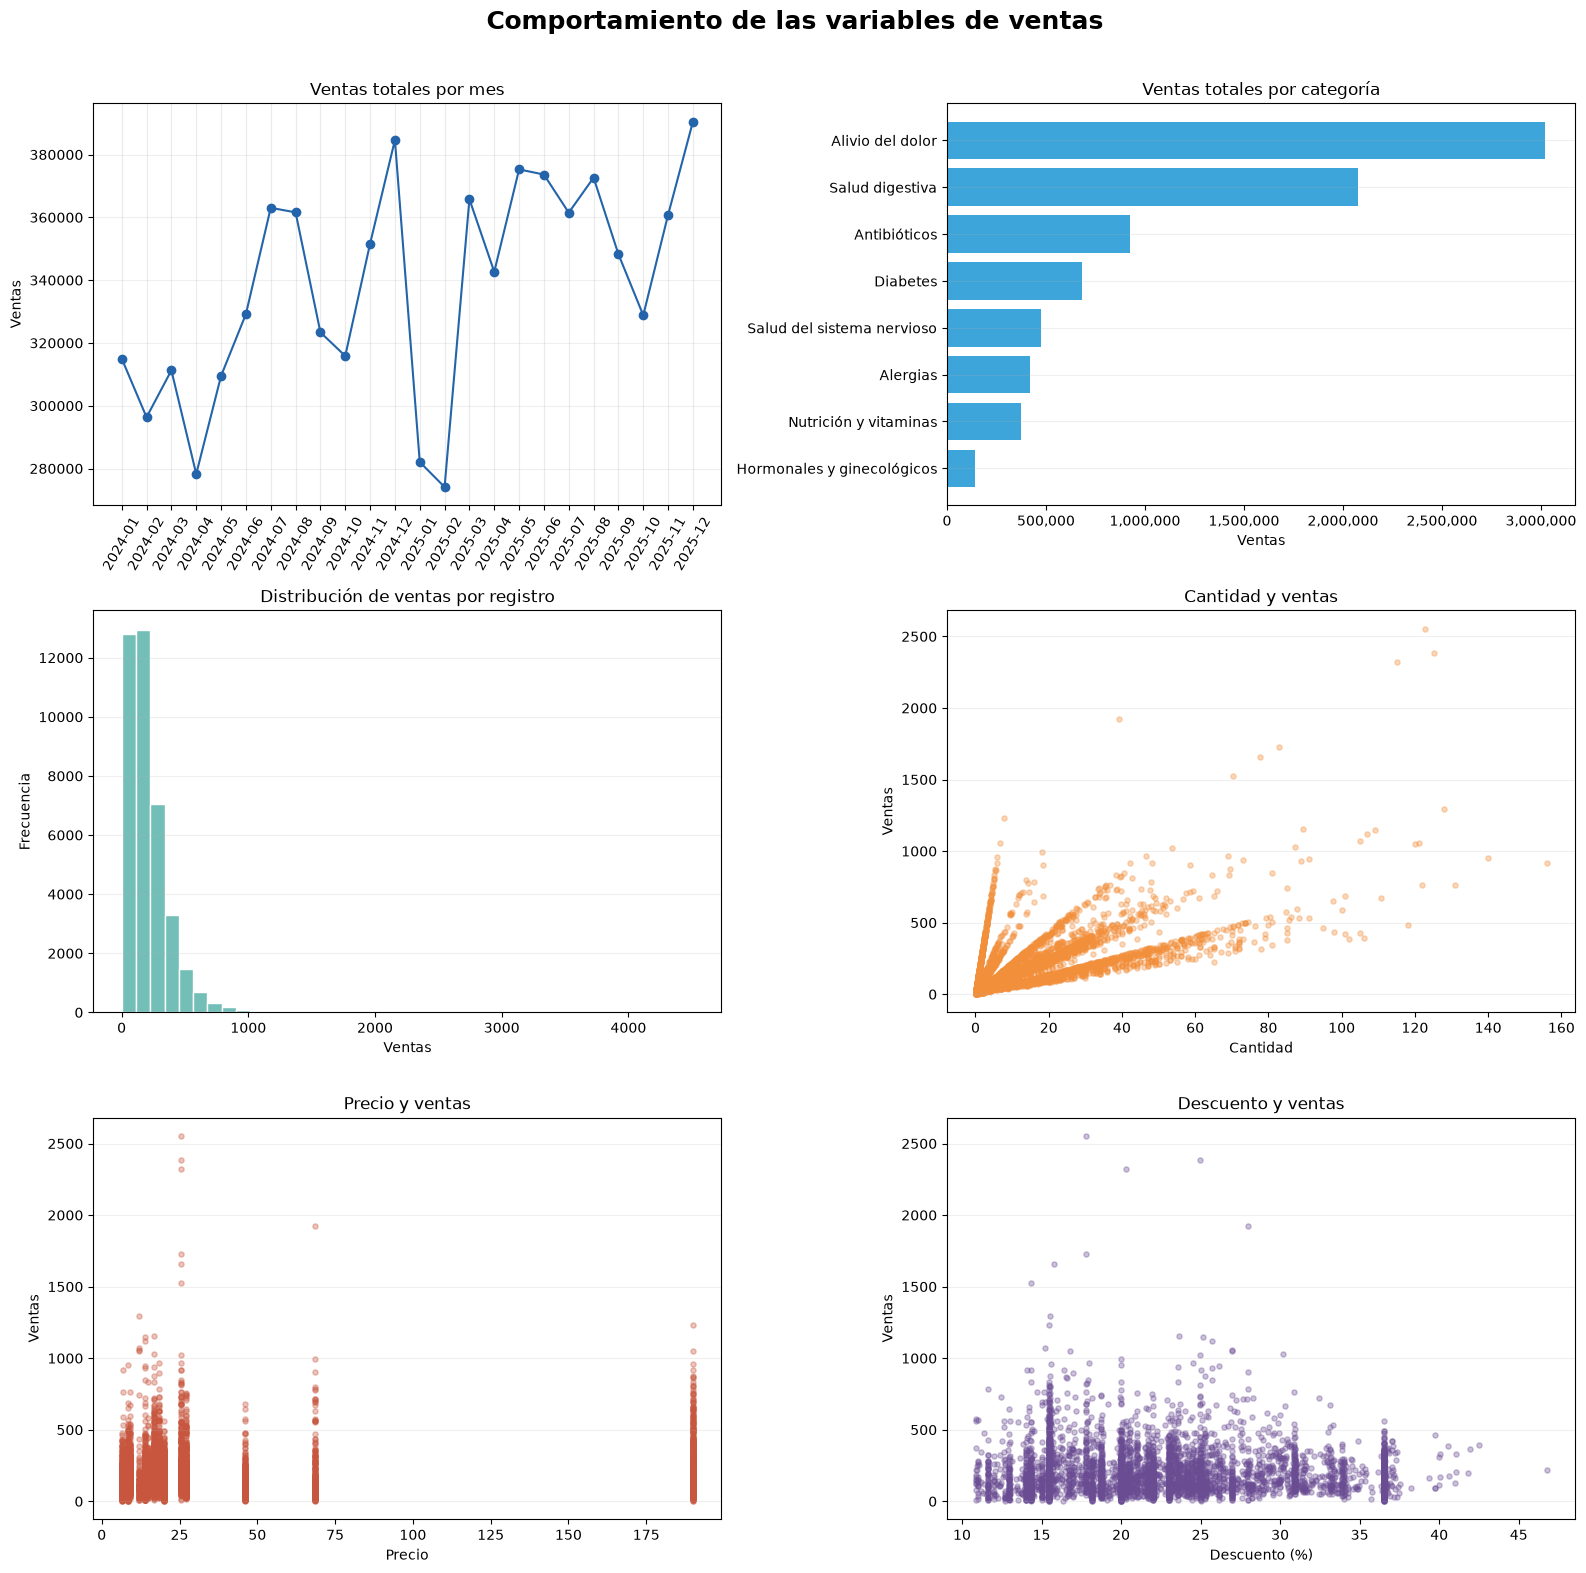

Graficos guardados en: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\graficos_comportamiento_ventas.png


In [8]:
monthly_sales = {}
category_sales = {}
for row in clean_rows:
    monthly_sales[row["periodo"]] = monthly_sales.get(row["periodo"], 0) + row["ventas"]
    category_sales[row["categoria"]] = category_sales.get(row["categoria"], 0) + row["ventas"]

months = sorted(monthly_sales)
categories = sorted(category_sales, key=category_sales.get)
ventas = [row["ventas"] for row in clean_rows]
cantidad = [row["cantidad"] for row in clean_rows]
precio = [row["precio"] for row in clean_rows]
descuento_pct = [row["descuento_pct"] * 100 for row in clean_rows]

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
fig.suptitle("Comportamiento de las variables de ventas", fontsize=18, fontweight="bold")

axes[0, 0].plot(months, [monthly_sales[m] for m in months], marker="o", color="#2364AA")
axes[0, 0].set_title("Ventas totales por mes")
axes[0, 0].set_ylabel("Ventas")
axes[0, 0].tick_params(axis="x", rotation=60)
axes[0, 0].grid(alpha=0.25)

axes[0, 1].barh(categories, [category_sales[c] for c in categories], color="#3DA5D9")
axes[0, 1].set_title("Ventas totales por categoría")
axes[0, 1].set_xlabel("Ventas")
axes[0, 1].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))

axes[1, 0].hist(ventas, bins=40, color="#73BFB8", edgecolor="white")
axes[1, 0].set_title("Distribución de ventas por registro")
axes[1, 0].set_xlabel("Ventas")
axes[1, 0].set_ylabel("Frecuencia")

sample = clean_rows[::max(1, len(clean_rows) // 4000)]
axes[1, 1].scatter([r["cantidad"] for r in sample], [r["ventas"] for r in sample], alpha=0.35, s=14, color="#F28F3B")
axes[1, 1].set_title("Cantidad y ventas")
axes[1, 1].set_xlabel("Cantidad")
axes[1, 1].set_ylabel("Ventas")

axes[2, 0].scatter([r["precio"] for r in sample], [r["ventas"] for r in sample], alpha=0.35, s=14, color="#C8553D")
axes[2, 0].set_title("Precio y ventas")
axes[2, 0].set_xlabel("Precio")
axes[2, 0].set_ylabel("Ventas")

axes[2, 1].scatter([r["descuento_pct"] * 100 for r in sample], [r["ventas"] for r in sample], alpha=0.35, s=14, color="#6A4C93")
axes[2, 1].set_title("Descuento y ventas")
axes[2, 1].set_xlabel("Descuento (%)")
axes[2, 1].set_ylabel("Ventas")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout(rect=(0, 0, 1, 0.97))

output_path = BASE_DIR / "graficos_comportamiento_ventas.png"
fig.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Graficos guardados en: {output_path}")

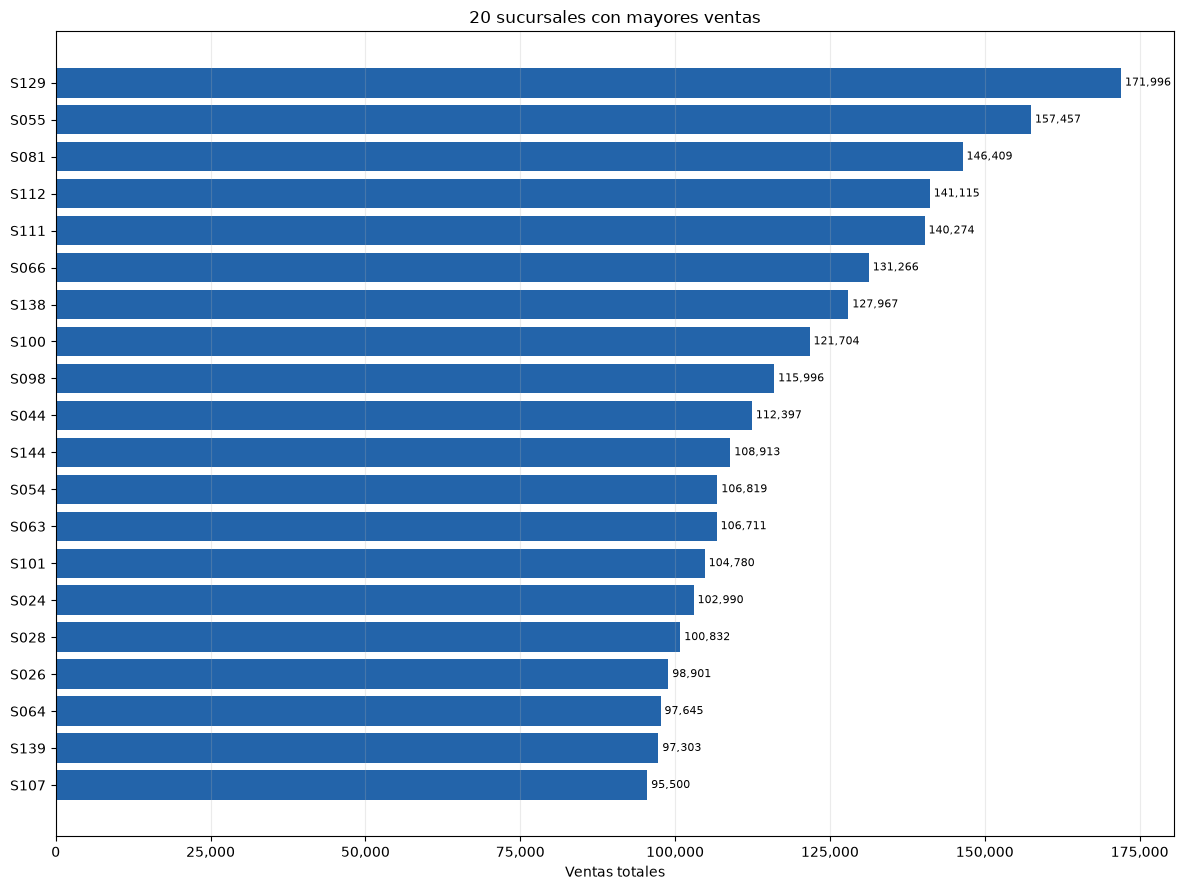

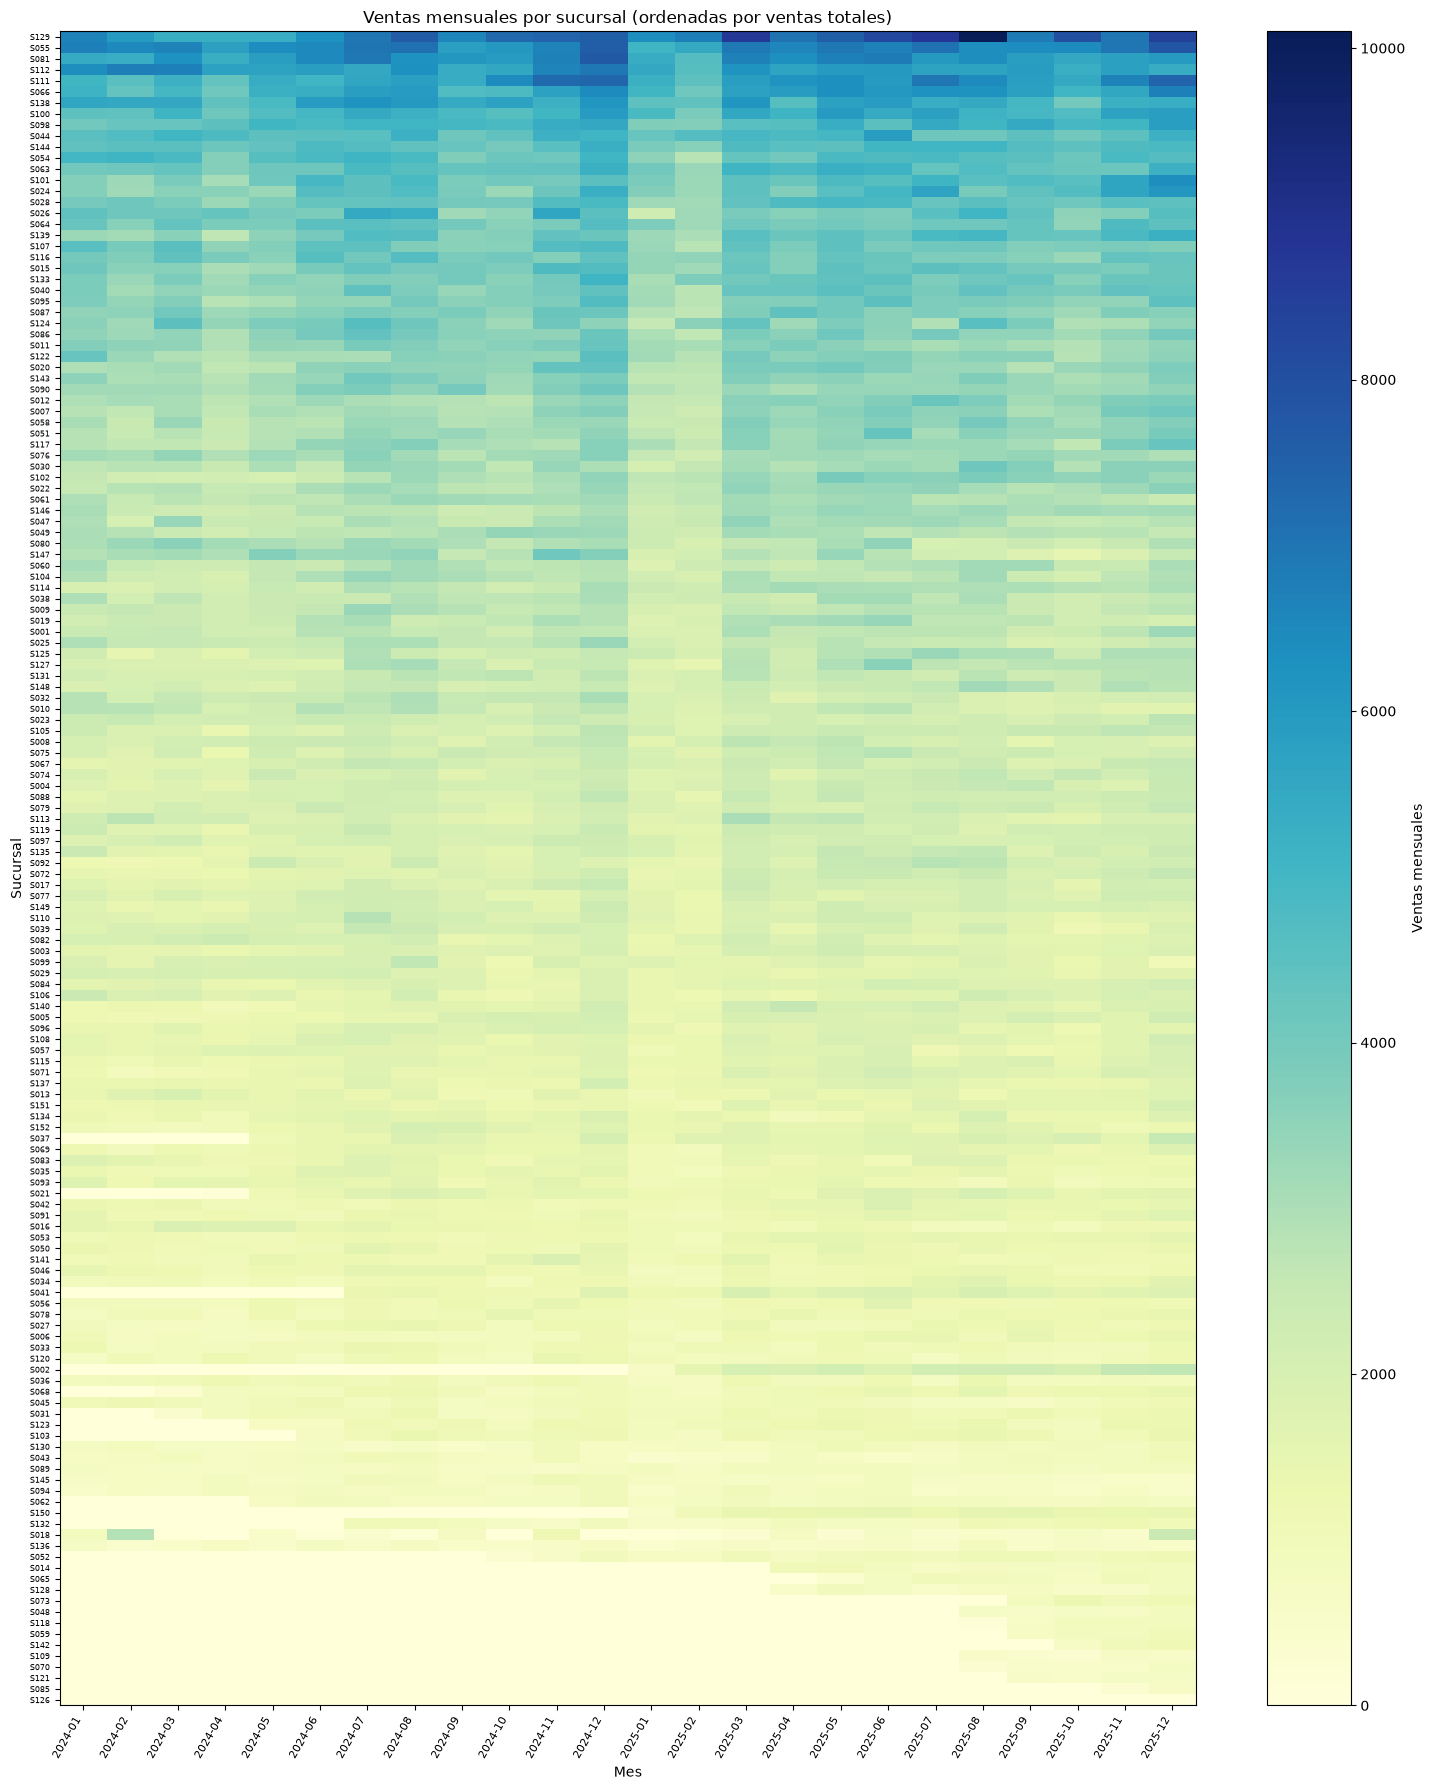

Sucursales analizadas: 152
Mayor venta total: S129 (171,996.35)
Graficos guardados: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_top_20_sucursales.png y c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_mensuales_por_sucursal.png
Resumen de las 152 sucursales: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\resumen_ventas_por_sucursal.csv


In [9]:
branch_totals = {}
branch_monthly = {}
for row in clean_rows:
    branch = row["sucursal"]
    branch_totals[branch] = branch_totals.get(branch, 0) + row["ventas"]
    monthly = branch_monthly.setdefault(branch, {})
    monthly[row["periodo"]] = monthly.get(row["periodo"], 0) + row["ventas"]

branch_order = sorted(branch_totals, key=branch_totals.get, reverse=True)
top_branches = list(reversed(branch_order[:20]))
fig, ax = plt.subplots(figsize=(12, 9))
bars = ax.barh(top_branches, [branch_totals[b] for b in top_branches], color="#2364AA")
ax.set_title("20 sucursales con mayores ventas")
ax.set_xlabel("Ventas totales")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.grid(axis="x", alpha=0.25)
for bar in bars:
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {bar.get_width():,.0f}", va="center", fontsize=8)
fig.tight_layout()
ranking_path = BASE_DIR / "ventas_top_20_sucursales.png"
fig.savefig(ranking_path, dpi=160, bbox_inches="tight")
plt.show()

months = sorted({row["periodo"] for row in clean_rows})
matrix = [[branch_monthly[branch].get(month, 0) for month in months] for branch in branch_order]
fig, ax = plt.subplots(figsize=(15, 18))
image = ax.imshow(matrix, aspect="auto", interpolation="nearest", cmap="YlGnBu")
ax.set_title("Ventas mensuales por sucursal (ordenadas por ventas totales)")
ax.set_xlabel("Mes")
ax.set_ylabel("Sucursal")
ax.set_xticks(range(len(months)))
ax.set_xticklabels(months, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(branch_order)))
ax.set_yticklabels(branch_order, fontsize=6)
fig.colorbar(image, ax=ax, label="Ventas mensuales")
fig.tight_layout()
heatmap_path = BASE_DIR / "ventas_mensuales_por_sucursal.png"
fig.savefig(heatmap_path, dpi=160, bbox_inches="tight")
plt.show()

branch_report = BASE_DIR / "resumen_ventas_por_sucursal.csv"
with branch_report.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["sucursal", "ventas_totales", "participacion_pct", "meses_con_ventas", "ventas_promedio_mensual"])
    writer.writeheader()
    total_sales = sum(branch_totals.values())
    for branch in branch_order:
        monthly_values = list(branch_monthly[branch].values())
        writer.writerow({
            "sucursal": branch,
            "ventas_totales": round(branch_totals[branch], 2),
            "participacion_pct": round(branch_totals[branch] / total_sales * 100, 2),
            "meses_con_ventas": len(monthly_values),
            "ventas_promedio_mensual": round(sum(monthly_values) / len(monthly_values), 2),
        })

print(f"Sucursales analizadas: {len(branch_order)}")
print(f"Mayor venta total: {branch_order[0]} ({branch_totals[branch_order[0]]:,.2f})")
print(f"Graficos guardados: {ranking_path} y {heatmap_path}")
print(f"Resumen de las 152 sucursales: {branch_report}")

10 SUCURSALES CON MAYOR DESCUENTO PROMEDIO
 1. S018: promedio=26.89%; mediana=24.96%; registros=70
 2. S111: promedio=23.85%; mediana=22.96%; registros=285
 3. S100: promedio=23.84%; mediana=23.00%; registros=286
 4. S101: promedio=23.74%; mediana=22.80%; registros=285
 5. S024: promedio=23.71%; mediana=22.93%; registros=286
 6. S066: promedio=23.71%; mediana=22.85%; registros=286
 7. S063: promedio=23.62%; mediana=22.78%; registros=285
 8. S117: promedio=23.59%; mediana=22.73%; registros=284
 9. S150: promedio=23.38%; mediana=22.75%; registros=141
10. S068: promedio=23.37%; mediana=22.00%; registros=252


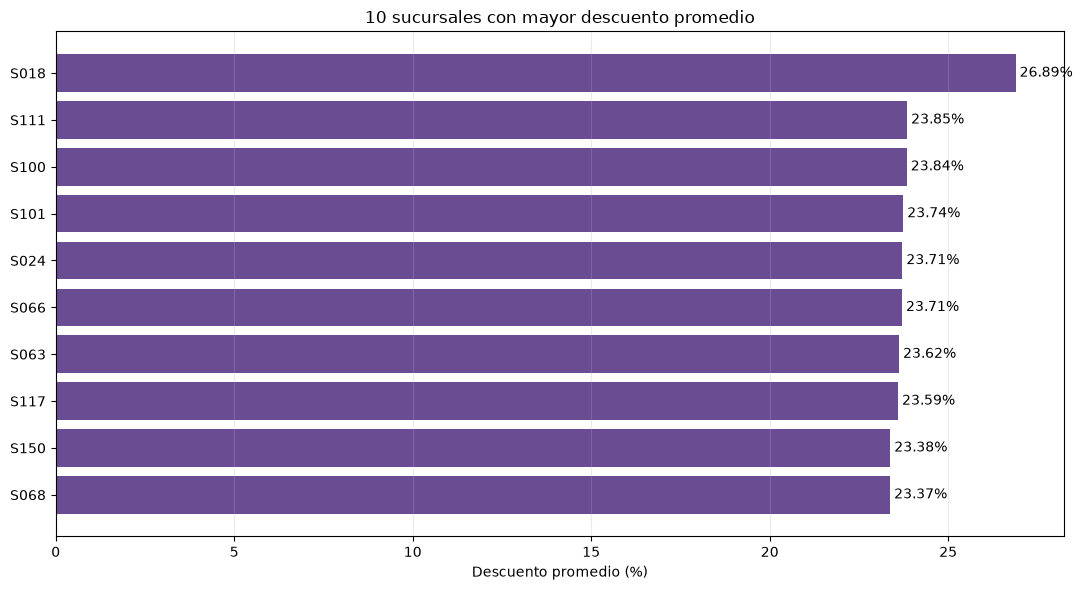

Ranking guardado en: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\top_10_sucursales_por_descuento.csv
Grafico guardado en: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\top_10_sucursales_por_descuento.png


In [10]:
discount_by_branch = {}
for row in clean_rows:
    branch = row["sucursal"]
    group = discount_by_branch.setdefault(branch, {"discounts": [], "sales": 0.0})
    group["discounts"].append(row["descuento_pct"])
    group["sales"] += row["ventas"]

discount_ranking = []
for branch, group in discount_by_branch.items():
    rates = group["discounts"]
    discount_ranking.append({
        "sucursal": branch,
        "descuento_promedio_pct": sum(rates) / len(rates) * 100,
        "descuento_mediano_pct": median(rates) * 100,
        "registros": len(rates),
        "ventas_totales": group["sales"],
    })

discount_ranking.sort(key=lambda item: item["descuento_promedio_pct"], reverse=True)
top_10_discount = discount_ranking[:10]

print("10 SUCURSALES CON MAYOR DESCUENTO PROMEDIO")
for position, item in enumerate(top_10_discount, 1):
    print(f"{position:2}. {item['sucursal']}: promedio={item['descuento_promedio_pct']:.2f}%; mediana={item['descuento_mediano_pct']:.2f}%; registros={item['registros']:,}")

discount_path = BASE_DIR / "top_10_sucursales_por_descuento.csv"
with discount_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["sucursal", "descuento_promedio_pct", "descuento_mediano_pct", "registros", "ventas_totales"])
    writer.writeheader()
    for item in top_10_discount:
        writer.writerow({**item, "descuento_promedio_pct": round(item["descuento_promedio_pct"], 2), "descuento_mediano_pct": round(item["descuento_mediano_pct"], 2), "ventas_totales": round(item["ventas_totales"], 2)})

chart_branches = list(reversed(top_10_discount))
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh([item["sucursal"] for item in chart_branches], [item["descuento_promedio_pct"] for item in chart_branches], color="#6A4C93")
ax.set_title("10 sucursales con mayor descuento promedio")
ax.set_xlabel("Descuento promedio (%)")
ax.grid(axis="x", alpha=0.25)
for bar in bars:
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {bar.get_width():.2f}%", va="center")
fig.tight_layout()
discount_chart_path = BASE_DIR / "top_10_sucursales_por_descuento.png"
fig.savefig(discount_chart_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Ranking guardado en: {discount_path}")
print(f"Grafico guardado en: {discount_chart_path}")

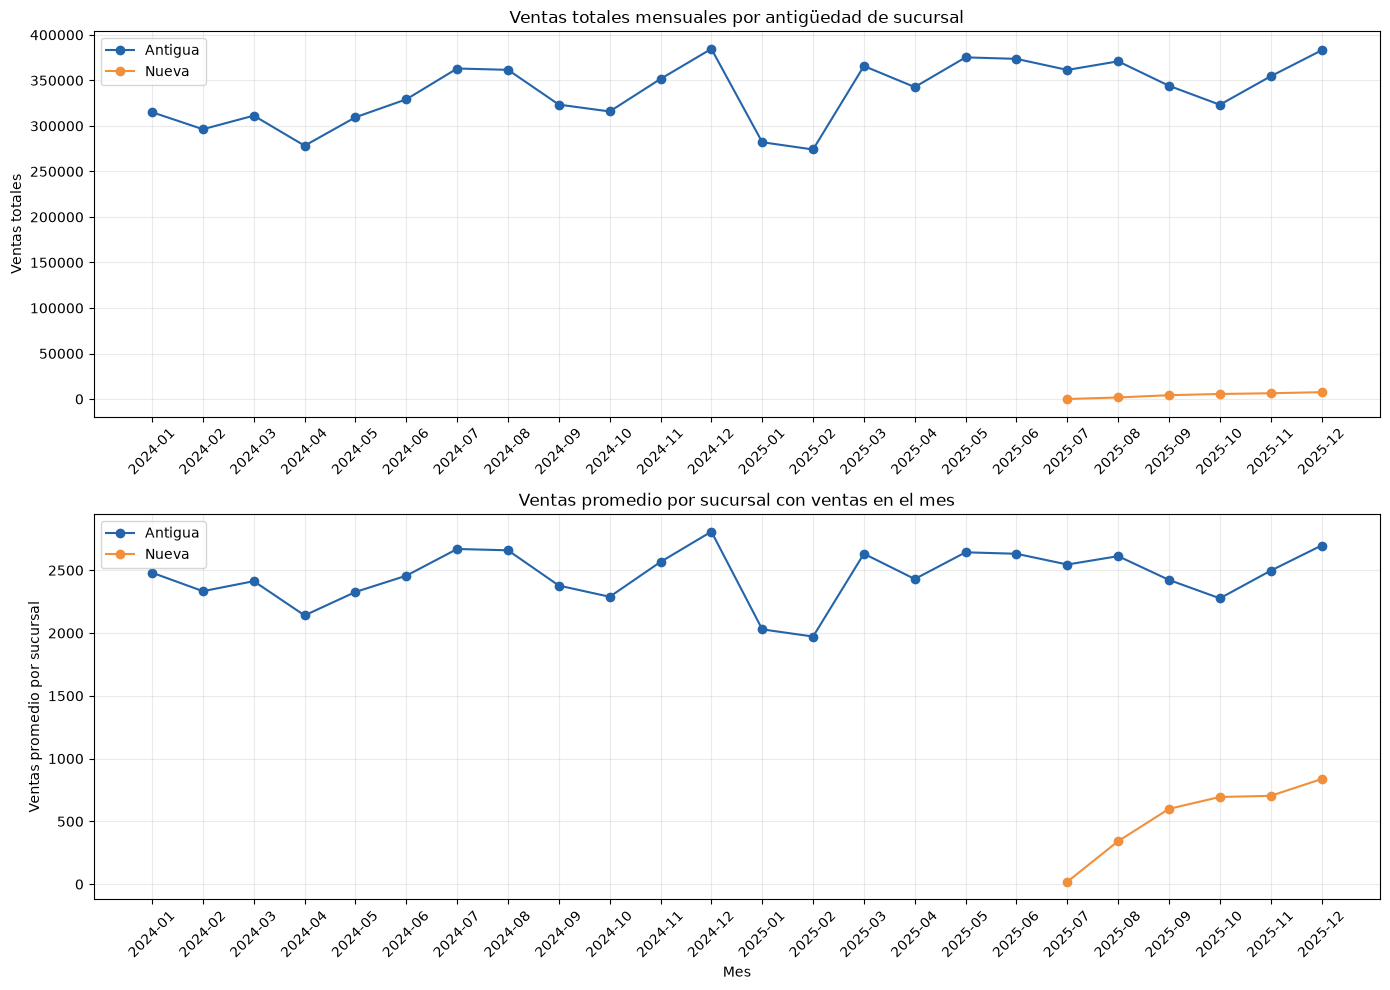

Criterio: nueva = primera venta registrada desde 2025-06
Sucursales nuevas (9): S048 (2025-07), S070 (2025-08), S073 (2025-08), S109 (2025-08), S118 (2025-08), S059 (2025-09), S121 (2025-09), S142 (2025-10), S085 (2025-11)

Comparacion por grupo (ventas promedio normalizadas por mes activo):
Antigua: 143 sucursales; ventas totales=8,090,466.92; promedio por sucursal-mes activo=2,456.12
Nueva: 9 sucursales; ventas totales=25,348.68; promedio por sucursal-mes activo=649.97

Grafico: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_sucursales_nuevas_vs_antiguas.png
Resumen por grupo: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\comparacion_sucursales_nuevas_antiguas.csv
Detalle de sucursales y primera venta: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\detalle_sucursales_nuevas_antiguas.csv


In [11]:
NEW_BRANCH_CUTOFF = "2025-06"
branch_first_month = {}
branch_month_sales = {}
for row in clean_rows:
    branch = row["sucursal"]
    month = row["periodo"]
    branch_first_month[branch] = min(branch_first_month.get(branch, month), month)
    monthly_sales = branch_month_sales.setdefault(branch, {})
    monthly_sales[month] = monthly_sales.get(month, 0) + row["ventas"]

branch_cohort = {
    branch: "Nueva" if first_month >= NEW_BRANCH_CUTOFF else "Antigua"
    for branch, first_month in branch_first_month.items()
}
all_months = sorted({row["periodo"] for row in clean_rows})
cohort_monthly_sales = {"Nueva": {}, "Antigua": {}}
cohort_monthly_branches = {"Nueva": {}, "Antigua": {}}
branch_details = []

for branch, first_month in branch_first_month.items():
    cohort = branch_cohort[branch]
    months_active = branch_month_sales[branch]
    total_branch_sales = sum(months_active.values())
    branch_details.append({
        "sucursal": branch,
        "grupo": cohort,
        "primera_venta_observada": first_month,
        "meses_con_ventas": len(months_active),
        "ventas_totales": total_branch_sales,
        "ventas_promedio_mes_activo": total_branch_sales / len(months_active),
    })
    for month, sales in months_active.items():
        cohort_monthly_sales[cohort][month] = cohort_monthly_sales[cohort].get(month, 0) + sales
        cohort_monthly_branches[cohort][month] = cohort_monthly_branches[cohort].get(month, 0) + 1

cohort_summary = []
for cohort in ("Antigua", "Nueva"):
    branches = [item for item in branch_details if item["grupo"] == cohort]
    total_sales = sum(item["ventas_totales"] for item in branches)
    total_branch_months = sum(item["meses_con_ventas"] for item in branches)
    cohort_summary.append({
        "grupo": cohort,
        "sucursales": len(branches),
        "ventas_totales": total_sales,
        "ventas_promedio_por_sucursal": total_sales / len(branches) if branches else 0,
        "ventas_promedio_por_sucursal_mes_activo": total_sales / total_branch_months if total_branch_months else 0,
        "meses_sucursal_activos": total_branch_months,
    })

summary_path = BASE_DIR / "comparacion_sucursales_nuevas_antiguas.csv"
with summary_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=list(cohort_summary[0].keys()))
    writer.writeheader()
    writer.writerows(cohort_summary)

detail_path = BASE_DIR / "detalle_sucursales_nuevas_antiguas.csv"
with detail_path.open("w", encoding="utf-8-sig", newline="") as target:
    fieldnames = ["sucursal", "grupo", "primera_venta_observada", "meses_con_ventas", "ventas_totales", "ventas_promedio_mes_activo"]
    writer = csv.DictWriter(target, fieldnames=fieldnames)
    writer.writeheader()
    for item in sorted(branch_details, key=lambda value: (value["grupo"], value["primera_venta_observada"], value["sucursal"])):
        writer.writerow({**item, "ventas_totales": round(item["ventas_totales"], 2), "ventas_promedio_mes_activo": round(item["ventas_promedio_mes_activo"], 2)})

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
colors = {"Antigua": "#2364AA", "Nueva": "#F28F3B"}
for cohort in ("Antigua", "Nueva"):
    observed_months = [month for month in all_months if cohort_monthly_branches[cohort].get(month, 0) > 0]
    totals = [cohort_monthly_sales[cohort][month] for month in observed_months]
    averages = [cohort_monthly_sales[cohort][month] / cohort_monthly_branches[cohort][month] for month in observed_months]
    axes[0].plot(observed_months, totals, marker="o", label=cohort, color=colors[cohort])
    axes[1].plot(observed_months, averages, marker="o", label=cohort, color=colors[cohort])

axes[0].set_title("Ventas totales mensuales por antigüedad de sucursal")
axes[0].set_ylabel("Ventas totales")
axes[1].set_title("Ventas promedio por sucursal con ventas en el mes")
axes[1].set_ylabel("Ventas promedio por sucursal")
axes[1].set_xlabel("Mes")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
cohort_chart_path = BASE_DIR / "ventas_sucursales_nuevas_vs_antiguas.png"
fig.savefig(cohort_chart_path, dpi=160, bbox_inches="tight")
plt.show()

new_branches = sorted((item for item in branch_details if item["grupo"] == "Nueva"), key=lambda item: item["primera_venta_observada"])
print(f"Criterio: nueva = primera venta registrada desde {NEW_BRANCH_CUTOFF}")
print(f"Sucursales nuevas ({len(new_branches)}): " + ", ".join(f"{item['sucursal']} ({item['primera_venta_observada']})" for item in new_branches))
print("\nComparacion por grupo (ventas promedio normalizadas por mes activo):")
for item in cohort_summary:
    print(f"{item['grupo']}: {item['sucursales']} sucursales; ventas totales={item['ventas_totales']:,.2f}; promedio por sucursal-mes activo={item['ventas_promedio_por_sucursal_mes_activo']:,.2f}")
print(f"\nGrafico: {cohort_chart_path}")
print(f"Resumen por grupo: {summary_path}")
print(f"Detalle de sucursales y primera venta: {detail_path}")

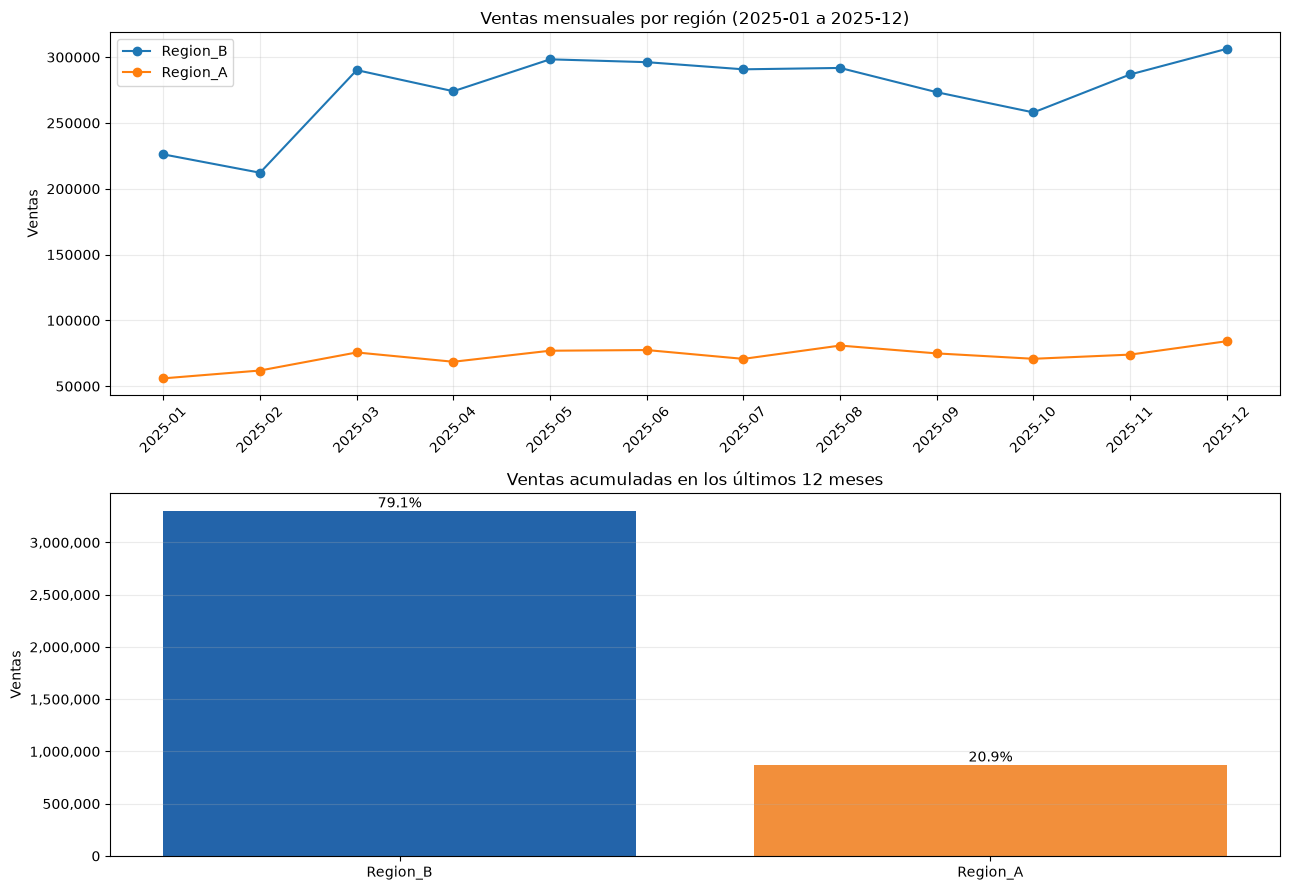

Periodo analizado: 2025-01 a 2025-12
Ventas por región:
- Region_B: total=3,304,050.62; promedio mensual=275,337.55; participación=79.12%
- Region_A: total=872,045.41; promedio mensual=72,670.45; participación=20.88%
Grafico: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_por_region_ultimos_12_meses.png
Resumen: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_por_region_ultimos_12_meses.csv
Detalle mensual: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\ventas_mensuales_por_region_ultimos_12_meses.csv


In [12]:
available_months = sorted({row["periodo"] for row in clean_rows})
recent_months = available_months[-12:]
if len(recent_months) < 12:
    raise ValueError("La base tiene menos de 12 meses disponibles")

region_monthly_sales = {}
region_totals = {}
for row in clean_rows:
    if row["periodo"] not in recent_months:
        continue
    region = row["region"]
    month = row["periodo"]
    region_totals[region] = region_totals.get(region, 0) + row["ventas"]
    monthly = region_monthly_sales.setdefault(region, {})
    monthly[month] = monthly.get(month, 0) + row["ventas"]

total_recent_sales = sum(region_totals.values())
region_summary = []
for region in sorted(region_totals, key=region_totals.get, reverse=True):
    region_summary.append({
        "region": region,
        "ventas_12_meses": region_totals[region],
        "participacion_pct": region_totals[region] / total_recent_sales * 100 if total_recent_sales else 0,
        "promedio_mensual": region_totals[region] / len(recent_months),
    })

regional_summary_path = BASE_DIR / "ventas_por_region_ultimos_12_meses.csv"
with regional_summary_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["region", "ventas_12_meses", "participacion_pct", "promedio_mensual"])
    writer.writeheader()
    for item in region_summary:
        writer.writerow({key: round(value, 2) if isinstance(value, float) else value for key, value in item.items()})

regional_monthly_path = BASE_DIR / "ventas_mensuales_por_region_ultimos_12_meses.csv"
with regional_monthly_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["periodo", "region", "ventas"])
    writer.writeheader()
    for month in recent_months:
        for region in sorted(region_monthly_sales):
            writer.writerow({"periodo": month, "region": region, "ventas": round(region_monthly_sales[region].get(month, 0), 2)})

fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for item in region_summary:
    region = item["region"]
    values = [region_monthly_sales[region].get(month, 0) for month in recent_months]
    axes[0].plot(recent_months, values, marker="o", label=region)
axes[0].set_title(f"Ventas mensuales por región ({recent_months[0]} a {recent_months[-1]})")
axes[0].set_ylabel("Ventas")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[0].tick_params(axis="x", rotation=45)

bars = axes[1].bar([item["region"] for item in region_summary], [item["ventas_12_meses"] for item in region_summary], color=["#2364AA", "#F28F3B"])
axes[1].set_title("Ventas acumuladas en los últimos 12 meses")
axes[1].set_ylabel("Ventas")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
axes[1].grid(axis="y", alpha=0.25)
for bar, item in zip(bars, region_summary):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{item['participacion_pct']:.1f}%", ha="center", va="bottom")
fig.tight_layout()
regional_chart_path = BASE_DIR / "ventas_por_region_ultimos_12_meses.png"
fig.savefig(regional_chart_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Periodo analizado: {recent_months[0]} a {recent_months[-1]}")
print("Ventas por región:")
for item in region_summary:
    print(f"- {item['region']}: total={item['ventas_12_meses']:,.2f}; promedio mensual={item['promedio_mensual']:,.2f}; participación={item['participacion_pct']:.2f}%")
print(f"Grafico: {regional_chart_path}")
print(f"Resumen: {regional_summary_path}")
print(f"Detalle mensual: {regional_monthly_path}")

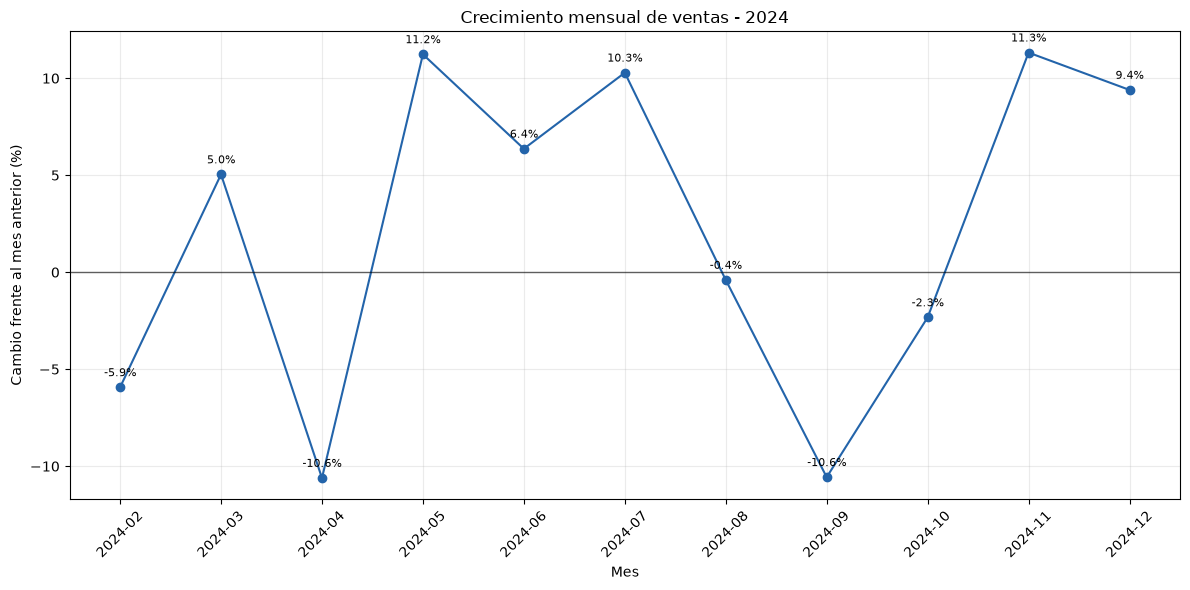

CRECIMIENTO MENSUAL DE VENTAS 2024
2024-01: ventas=315,029.10; crecimiento=sin comparación (no hay diciembre 2023)
2024-02: ventas=296,338.28; crecimiento=-5.93%
2024-03: ventas=311,274.16; crecimiento=+5.04%
2024-04: ventas=278,248.11; crecimiento=-10.61%
2024-05: ventas=309,500.11; crecimiento=+11.23%
2024-06: ventas=329,191.42; crecimiento=+6.36%
2024-07: ventas=363,044.10; crecimiento=+10.28%
2024-08: ventas=361,594.26; crecimiento=-0.40%
2024-09: ventas=323,389.05; crecimiento=-10.57%
2024-10: ventas=315,853.47; crecimiento=-2.33%
2024-11: ventas=351,609.49; crecimiento=+11.32%
2024-12: ventas=384,648.02; crecimiento=+9.40%

Tabla: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_mensual_ventas_2024.csv
Grafico: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_mensual_ventas_2024.png


In [13]:
sales_2024 = {}
for row in clean_rows:
    if row["periodo"].startswith("2024-"):
        sales_2024[row["periodo"]] = sales_2024.get(row["periodo"], 0) + row["ventas"]

months_2024 = sorted(sales_2024)
if len(months_2024) != 12:
    raise ValueError(f"Se esperaban 12 meses de 2024 y se encontraron {len(months_2024)}")

monthly_growth_2024 = []
for index, month in enumerate(months_2024):
    previous_month = months_2024[index - 1] if index > 0 else None
    previous_sales = sales_2024[previous_month] if previous_month else None
    growth_pct = ((sales_2024[month] - previous_sales) / previous_sales * 100) if previous_sales else None
    monthly_growth_2024.append({
        "periodo": month,
        "ventas": sales_2024[month],
        "ventas_mes_anterior": previous_sales,
        "crecimiento_mensual_pct": growth_pct,
    })

growth_csv_path = BASE_DIR / "crecimiento_mensual_ventas_2024.csv"
with growth_csv_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["periodo", "ventas", "ventas_mes_anterior", "crecimiento_mensual_pct"])
    writer.writeheader()
    for item in monthly_growth_2024:
        writer.writerow({key: round(value, 2) if isinstance(value, float) else value for key, value in item.items()})

growth_months = [item["periodo"] for item in monthly_growth_2024[1:]]
growth_values = [item["crecimiento_mensual_pct"] for item in monthly_growth_2024[1:]]
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(growth_months, growth_values, marker="o", color="#2364AA")
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("Crecimiento mensual de ventas - 2024")
ax.set_xlabel("Mes")
ax.set_ylabel("Cambio frente al mes anterior (%)")
ax.grid(alpha=0.25)
ax.tick_params(axis="x", rotation=45)
for month, value in zip(growth_months, growth_values):
    ax.annotate(f"{value:.1f}%", (month, value), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
fig.tight_layout()
growth_chart_path = BASE_DIR / "crecimiento_mensual_ventas_2024.png"
fig.savefig(growth_chart_path, dpi=160, bbox_inches="tight")
plt.show()

print("CRECIMIENTO MENSUAL DE VENTAS 2024")
for item in monthly_growth_2024:
    rate = "sin comparación (no hay diciembre 2023)" if item["crecimiento_mensual_pct"] is None else f"{item['crecimiento_mensual_pct']:+.2f}%"
    print(f"{item['periodo']}: ventas={item['ventas']:,.2f}; crecimiento={rate}")
print(f"\nTabla: {growth_csv_path}")
print(f"Grafico: {growth_chart_path}")

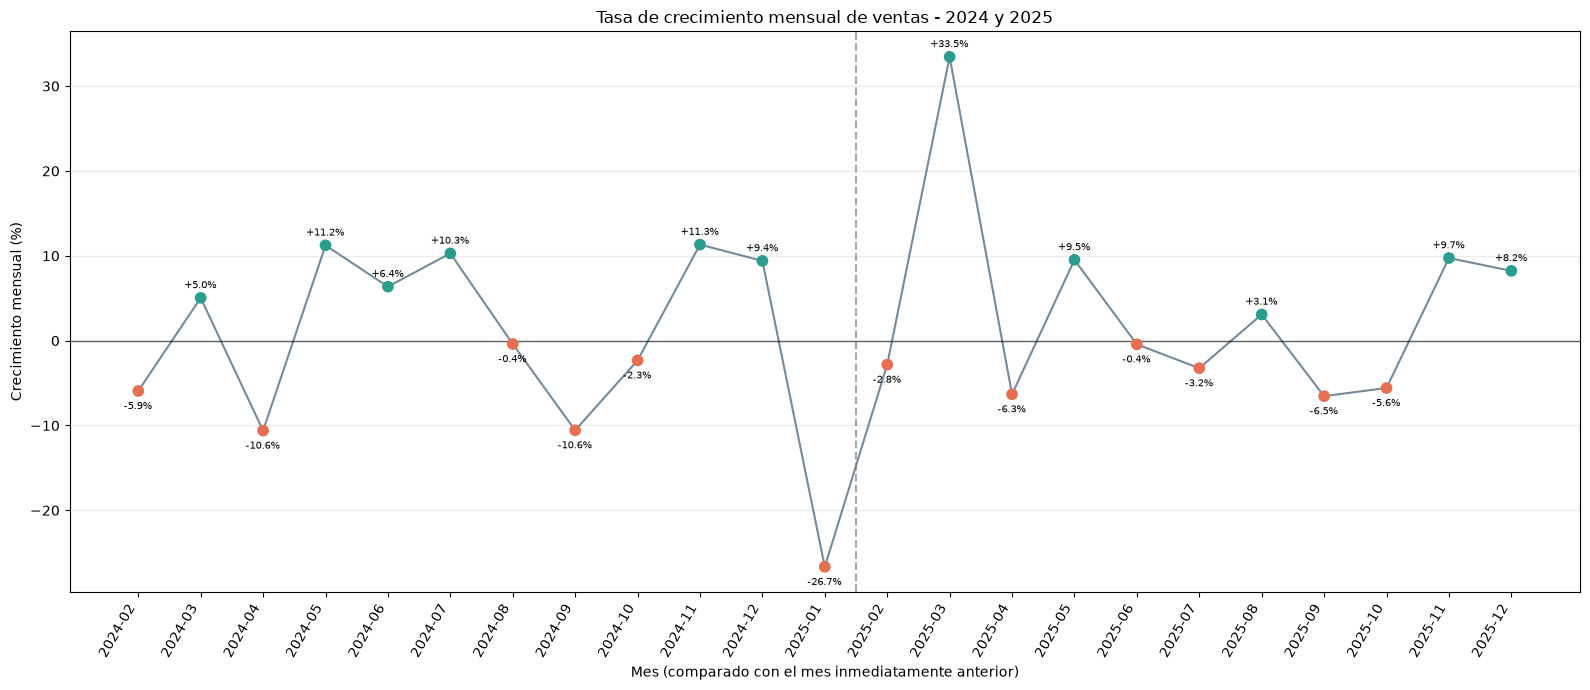

Periodo: 2024-01 a 2025-12; enero de 2024 no tiene mes previo en la base.
Mayor crecimiento: 2025-03 (+33.45%)
Mayor caída: 2025-01 (-26.67%)
Grafico: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_mensual_ventas_2024_2025.png
Tabla: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_mensual_ventas_2024_2025.csv


In [16]:
sales_2024_2025 = {}
for row in clean_rows:
    if row["periodo"].startswith(("2024-", "2025-")):
        sales_2024_2025[row["periodo"]] = sales_2024_2025.get(row["periodo"], 0) + row["ventas"]

months_2024_2025 = sorted(sales_2024_2025)
if len(months_2024_2025) != 24:
    raise ValueError(f"Se esperaban 24 meses entre 2024 y 2025 y se encontraron {len(months_2024_2025)}")

growth_2024_2025 = []
for index, month in enumerate(months_2024_2025):
    previous_month = months_2024_2025[index - 1] if index > 0 else None
    previous_sales = sales_2024_2025[previous_month] if previous_month else None
    rate = (sales_2024_2025[month] - previous_sales) / previous_sales * 100 if previous_sales else None
    growth_2024_2025.append({
        "periodo": month,
        "ventas": sales_2024_2025[month],
        "ventas_mes_anterior": previous_sales,
        "crecimiento_mensual_pct": rate,
    })

growth_2y_csv = BASE_DIR / "crecimiento_mensual_ventas_2024_2025.csv"
with growth_2y_csv.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["periodo", "ventas", "ventas_mes_anterior", "crecimiento_mensual_pct"])
    writer.writeheader()
    for item in growth_2024_2025:
        writer.writerow({key: round(value, 2) if isinstance(value, float) else value for key, value in item.items()})

plot_data = growth_2024_2025[1:]
plot_months = [item["periodo"] for item in plot_data]
plot_rates = [item["crecimiento_mensual_pct"] for item in plot_data]
plot_colors = ["#2A9D8F" if value >= 0 else "#E76F51" for value in plot_rates]
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(range(len(plot_months)), plot_rates, color="#526D82", linewidth=1.5, alpha=0.8)
ax.scatter(range(len(plot_months)), plot_rates, c=plot_colors, s=55, zorder=3)
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.axvline(11.5, color="gray", linestyle="--", alpha=0.7)
ax.set_xticks(range(len(plot_months)))
ax.set_xticklabels(plot_months, rotation=60, ha="right")
ax.set_title("Tasa de crecimiento mensual de ventas - 2024 y 2025")
ax.set_xlabel("Mes (comparado con el mes inmediatamente anterior)")
ax.set_ylabel("Crecimiento mensual (%)")
ax.grid(axis="y", alpha=0.25)
for index, value in enumerate(plot_rates):
    offset = 7 if value >= 0 else -13
    ax.annotate(f"{value:+.1f}%", (index, value), textcoords="offset points", xytext=(0, offset), ha="center", fontsize=7)
fig.tight_layout()
growth_2y_chart = BASE_DIR / "crecimiento_mensual_ventas_2024_2025.png"
fig.savefig(growth_2y_chart, dpi=160, bbox_inches="tight")
plt.show()

highest_growth = max(plot_data, key=lambda item: item["crecimiento_mensual_pct"])
lowest_growth = min(plot_data, key=lambda item: item["crecimiento_mensual_pct"])
print("Periodo: 2024-01 a 2025-12; enero de 2024 no tiene mes previo en la base.")
print(f"Mayor crecimiento: {highest_growth['periodo']} ({highest_growth['crecimiento_mensual_pct']:+.2f}%)")
print(f"Mayor caída: {lowest_growth['periodo']} ({lowest_growth['crecimiento_mensual_pct']:+.2f}%)")
print(f"Grafico: {growth_2y_chart}")
print(f"Tabla: {growth_2y_csv}")

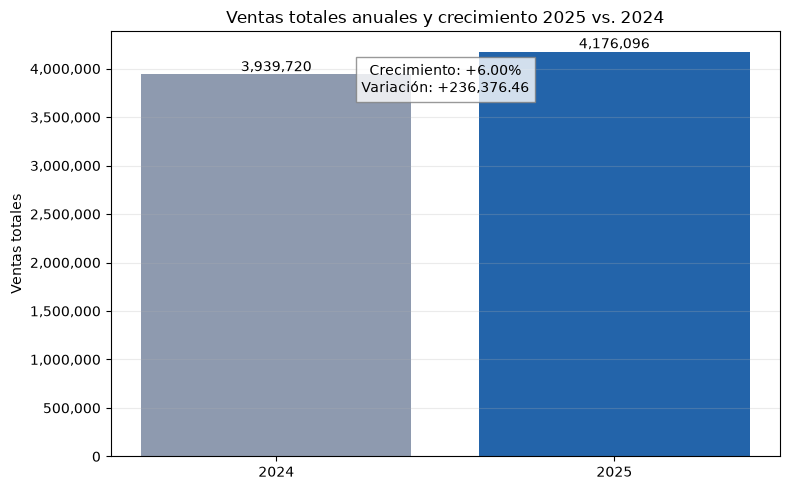

Ventas 2024: 3,939,719.57
Ventas 2025: 4,176,096.03
Variación absoluta 2025 vs. 2024: +236,376.46
Tasa de crecimiento anual: +6.00%
Grafico: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_anual_ventas_2024_2025.png
Tabla: c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\Nueva carpeta\crecimiento_anual_ventas_2024_2025.csv


In [17]:
annual_sales = {2024: 0.0, 2025: 0.0}
for row in clean_rows:
    year = int(row["anio"])
    if year in annual_sales:
        annual_sales[year] += row["ventas"]

if annual_sales[2024] == 0:
    raise ZeroDivisionError("No se puede calcular el crecimiento porque las ventas de 2024 son cero")

absolute_growth = annual_sales[2025] - annual_sales[2024]
annual_growth_pct = absolute_growth / annual_sales[2024] * 100
annual_comparison = [
    {"anio": 2024, "ventas_totales": annual_sales[2024], "variacion_vs_2024": 0.0, "crecimiento_pct_vs_2024": 0.0},
    {"anio": 2025, "ventas_totales": annual_sales[2025], "variacion_vs_2024": absolute_growth, "crecimiento_pct_vs_2024": annual_growth_pct},
]

annual_csv_path = BASE_DIR / "crecimiento_anual_ventas_2024_2025.csv"
with annual_csv_path.open("w", encoding="utf-8-sig", newline="") as target:
    writer = csv.DictWriter(target, fieldnames=["anio", "ventas_totales", "variacion_vs_2024", "crecimiento_pct_vs_2024"])
    writer.writeheader()
    for item in annual_comparison:
        writer.writerow({key: round(value, 2) if isinstance(value, float) else value for key, value in item.items()})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["2024", "2025"], [annual_sales[2024], annual_sales[2025]], color=["#8E9AAF", "#2364AA"])
ax.set_title("Ventas totales anuales y crecimiento 2025 vs. 2024")
ax.set_ylabel("Ventas totales")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.grid(axis="y", alpha=0.25)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{bar.get_height():,.0f}", ha="center", va="bottom")
ax.text(0.5, max(annual_sales.values()) * 0.9, f"Crecimiento: {annual_growth_pct:+.2f}%\nVariación: {absolute_growth:+,.2f}", ha="center", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "gray"})
fig.tight_layout()
annual_chart_path = BASE_DIR / "crecimiento_anual_ventas_2024_2025.png"
fig.savefig(annual_chart_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Ventas 2024: {annual_sales[2024]:,.2f}")
print(f"Ventas 2025: {annual_sales[2025]:,.2f}")
print(f"Variación absoluta 2025 vs. 2024: {absolute_growth:+,.2f}")
print(f"Tasa de crecimiento anual: {annual_growth_pct:+.2f}%")
print(f"Grafico: {annual_chart_path}")
print(f"Tabla: {annual_csv_path}")